# Résultats V2 : l'évaluation unique, relue à partir des preuves

Ce notebook relit l'**unique** évaluation du test V2 (11 novembre 2026). Elle a été faite après le gel par empreintes des systèmes, des poids, du code et de l'environnement (verrou 3).

- **Ce qu'il lit** : uniquement les preuves versionnées dans `reports/v2/`, à savoir le rapport final, les prédictions par morceau et l'analyse d'interprétation.
- **Ce qu'il ne fait pas** : il ne charge ni audio ni poids, et ne réentraîne rien. Il tourne en quelques secondes juste après un clonage du dépôt.

Le protocole est décrit dans `docs/PROTOCOLE_V2.md`, la discussion complète dans `docs/RAPPORT_V2.md`.

In [1]:
import hashlib
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import f1_score

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FINAL = ROOT / "reports/v2/final_evaluation"
report = json.loads((FINAL / "report.json").read_text(encoding="utf-8"))
interpretation = json.loads((ROOT / "reports/v2/interpretation.json").read_text(encoding="utf-8"))
LABELS = json.loads((ROOT / "configs/labels.json").read_text(encoding="utf-8"))["labels"]

# The predictions file must be the one the report was computed from.
digest = hashlib.sha256((FINAL / "predictions.csv").read_bytes()).hexdigest()
assert digest == report["predictions_sha256"], "predictions.csv differs from the report"
predictions = pd.read_csv(FINAL / "predictions.csv", dtype={"track_id": str, "artist_id": str})

ACCENT, CONTEXT, SECOND, INK, MUTED, GRID = "#2a78d6", "#52514e", "#eb6834", "#0b0b0b", "#898781", "#e1e0d9"
NAMES = {"maest_layer12": "MAEST bloc 12 (V2)", "vit_block6_hpss": "ViT bloc 6 + HPSS (candidat V1)",
         "vit_block6": "ViT bloc 6", "vit": "ViT bloc 12", "cnn20_seed42": "CNN V1, graine 42",
         "cnn20_seed43": "CNN V1, graine 43", "cnn20_seed44": "CNN V1, graine 44",
         "cnn_v2_seed42": "CNN renforcé, graine 42", "cnn_v2_seed43": "CNN renforcé, graine 43",
         "cnn_v2_seed44": "CNN renforcé, graine 44"}
print(f"Empreinte des prédictions vérifiée. Morceaux : {report['test_tracks']} de test, "
      f"{report['ood_tracks']} hors domaine, {report['gospel_tracks']} Gospel.")

Empreinte des prédictions vérifiée. Morceaux : 501 de test, 340 hors domaine, 12 Gospel.


## 1. Les trois hypothèses préenregistrées

- **H1** est l'hypothèse primaire, testée au seuil α = 0,05.
- **H2 et H3** sont corrigées par la méthode de Holm.
- Les intervalles sont des BCa à 95 %, sur 5 000 tirages. Le test compte un morceau par artiste : rééchantillonner les morceaux revient donc à rééchantillonner les artistes.

In [2]:
rows = []
for name, h in report["hypotheses"].items():
    rows.append({"hypothèse": name, "rôle": h["role"], "système": NAMES[h["system"]],
                 "moins": " / ".join(NAMES[s] for s in h["minus_mean_of"]),
                 "différence": h["point"], "IC bas": h["low"], "IC haut": h["high"],
                 "p": h["p_value"], "p Holm": h.get("p_adjusted"), "rejetée (H0)": h["rejected"]})
pd.DataFrame(rows).set_index("hypothèse").round(4)

,rôle,système,moins,différence,IC bas,IC haut,p,p Holm,rejetée (H0)
hypothèse,,,,,,,,,
H1,primary,ViT bloc 6 + HPSS (candidat V1),ViT bloc 12,0.0276,-0.0065,0.0639,0.1183,NaN,False
H2,secondary,MAEST bloc 12 (V2),ViT bloc 6 + HPSS (candidat V1),0.0907,0.0487,0.1341,0.0002,0.0003,True
H3,secondary,MAEST bloc 12 (V2),"CNN renforcé, graine 42 / CNN renforcé, graine...",0.1175,0.0833,0.1542,0.0001,0.0003,True


**Lecture.**
- **H1 n'est pas concluante.** Le gain de la V1 garde son sens (+0,028), mais l'intervalle contient 0, et la puissance n'était que d'environ 56 %.
- **H2 et H3 sont confirmées.** MAEST dépasse à la fois le meilleur système V1 et le CNN renforcé.

## 2. Tous les systèmes sur le test V2

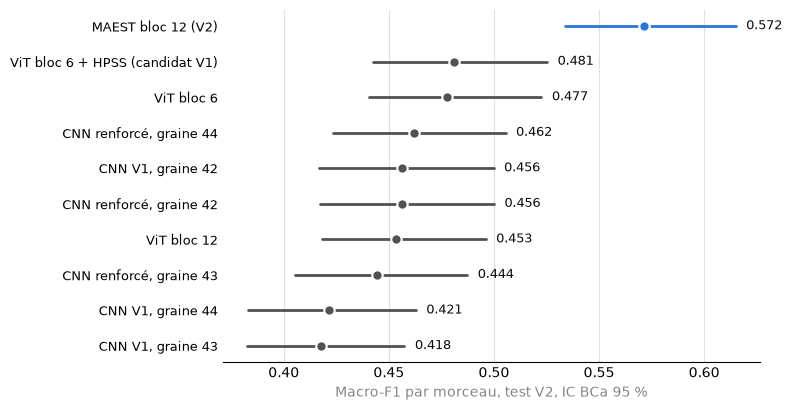

,macro-F1,IC bas,IC haut,accuracy
MAEST bloc 12 (V2),0.572,0.534,0.615,0.579
ViT bloc 6 + HPSS (candidat V1),0.481,0.442,0.525,0.491
ViT bloc 6,0.477,0.441,0.523,0.487
"CNN renforcé, graine 44",0.462,0.423,0.505,0.479
"CNN V1, graine 42",0.456,0.417,0.500,0.467
"CNN renforcé, graine 42",0.456,0.417,0.500,0.463
ViT bloc 12,0.453,0.418,0.496,0.469
"CNN renforcé, graine 43",0.444,0.405,0.487,0.459
"CNN V1, graine 44",0.421,0.383,0.463,0.439
"CNN V1, graine 43",0.418,0.383,0.457,0.439


In [3]:
order = sorted(report["systems"], key=lambda s: report["systems"][s]["macro_f1"]["point"])
fig, ax = plt.subplots(figsize=(8, 4.2))
for y, key in enumerate(order):
    f1 = report["systems"][key]["macro_f1"]
    color = ACCENT if key == "maest_layer12" else CONTEXT
    ax.plot([f1["low"], f1["high"]], [y, y], color=color, linewidth=2, solid_capstyle="round")
    ax.scatter(f1["point"], y, s=56, color=color, edgecolors="white", linewidths=1.5, zorder=3)
    ax.text(f1["high"] + 0.005, y, f"{f1['point']:.3f}", va="center", fontsize=9, color=INK)
ax.set_yticks(range(len(order)), [NAMES[k] for k in order], fontsize=9)
ax.set_xlabel("Macro-F1 par morceau, test V2, IC BCa 95 %", color=MUTED)
ax.grid(axis="x", color=GRID)
ax.set_axisbelow(True)
for side in ("top", "right", "left"):
    ax.spines[side].set_visible(False)
ax.tick_params(length=0)
plt.tight_layout()
plt.show()

pd.DataFrame({NAMES[k]: {"macro-F1": v["macro_f1"]["point"], "IC bas": v["macro_f1"]["low"],
                         "IC haut": v["macro_f1"]["high"], "accuracy": v["accuracy"]}
              for k, v in report["systems"].items()}).T.sort_values("macro-F1", ascending=False).round(3)

## 3. Vérification indépendante

On recalcule la macro-F1 de chaque système directement à partir des prédictions par morceau, avec scikit-learn, sans réutiliser le code d'évaluation. L'écart avec le rapport doit être nul.

In [4]:
test = predictions[predictions.role == "test"]
check = {}
for system, frame in test.groupby("system"):
    truth = frame.genre.map(LABELS.index)
    predicted = frame[[f"p_{label}" for label in LABELS]].to_numpy().argmax(axis=1)
    recomputed = f1_score(truth, predicted, labels=range(len(LABELS)), average="macro", zero_division=0)
    check[NAMES[system]] = abs(recomputed - report["systems"][system]["macro_f1"]["point"])
assert max(check.values()) < 1e-12
print(f"{len(check)} systèmes recomptés, écart maximal : {max(check.values()):.1e}")

10 systèmes recomptés, écart maximal : 0.0e+00


## 4. Par genre

Le tableau compare la macro-F1 hors pli du développement (validation croisée) avec celle du test, pour MAEST et pour le candidat V1.

In [5]:
genres = interpretation["by_genre"]
pd.DataFrame({
    "MAEST, développement": {g: v["development_oof"] for g, v in genres["maest_layer12"].items()},
    "MAEST, test V2": {g: v["v2_test"] for g, v in genres["maest_layer12"].items()},
    "candidat V1, développement": {g: v["development_oof"] for g, v in genres["vit_block6_hpss"].items()},
    "candidat V1, test V2": {g: v["v2_test"] for g, v in genres["vit_block6_hpss"].items()},
}).round(2)

,"MAEST, développement","MAEST, test V2","candidat V1, développement","candidat V1, test V2"
Electronic,0.74,0.60,0.58,0.51
Experimental,0.60,0.49,0.46,0.39
Folk,0.67,0.59,0.62,0.52
Hip-Hop,0.85,0.91,0.70,0.81
Instrumental,0.60,0.27,0.54,0.24
International,0.82,0.69,0.63,0.53
Pop,0.48,0.36,0.28,0.28
Rock,0.73,0.68,0.63,0.56


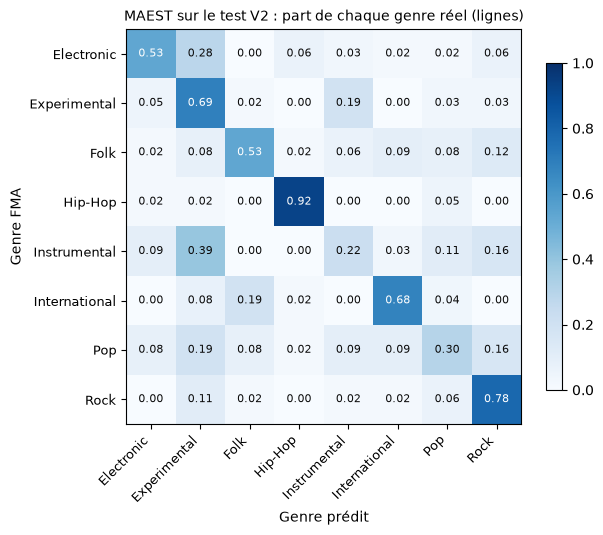

In [6]:
matrix = np.array(report["systems"]["maest_layer12"]["confusion_matrix"], dtype=float)
rates = matrix / matrix.sum(axis=1, keepdims=True)
fig, ax = plt.subplots(figsize=(6.4, 5.4))
image = ax.imshow(rates, cmap="Blues", vmin=0, vmax=1)
for i in range(len(LABELS)):
    for j in range(len(LABELS)):
        ax.text(j, i, f"{rates[i, j]:.2f}", ha="center", va="center", fontsize=8,
                color="white" if rates[i, j] > 0.5 else INK)
ax.set_xticks(range(len(LABELS)), LABELS, rotation=45, ha="right", fontsize=9)
ax.set_yticks(range(len(LABELS)), LABELS, fontsize=9)
ax.set_xlabel("Genre prédit")
ax.set_ylabel("Genre FMA")
ax.set_title("MAEST sur le test V2 : part de chaque genre réel (lignes)", fontsize=10)
fig.colorbar(image, ax=ax, shrink=0.8)
plt.tight_layout()
plt.show()

**Lecture.**
- Hip-Hop est le genre le mieux reconnu.
- Instrumental et Electronic partent souvent vers **Experimental**.
- L'écoute de 18 extraits mêle trois cas : des morceaux peu typés, des erreurs franches et quelques étiquettes discutables (`docs/INTERPRETATION_V2.md`).

## 5. Du développement au test

Plusieurs morceaux d'un même artiste peuvent figurer dans le développement, alors que le test n'en a qu'un par artiste. Le tableau ci-dessous donne trois mesures :
- la macro-F1 du développement, avec un poids égal par morceau ;
- la même, avec un poids égal par artiste ;
- la macro-F1 du test.

In [7]:
artists = interpretation["artists"]
display(pd.DataFrame({NAMES[s]: {"développement (par morceau)": v["development_track_weighted"],
                                 "développement (par artiste)": v["development_artist_weighted"],
                                 "test V2": v["v2_test_one_track_per_artist"]}
                      for s, v in artists.items() if s in NAMES}).T.round(3))
(pd.DataFrame(interpretation["by_genre"]["maest_confusions_that_grew"])
 .rename(columns={"true": "genre FMA", "predicted": "prédit par MAEST", "rate_change": "hausse du taux (test − dév.)"})
 .round(3))

,développement (par morceau),développement (par artiste),test V2
MAEST bloc 12 (V2),0.684,0.654,0.572
ViT bloc 6 + HPSS (candidat V1),0.553,0.518,0.481
ViT bloc 12,0.520,0.489,0.453


,genre FMA,prédit par MAEST,hausse du taux (test − dév.)
0,Instrumental,Experimental,0.257
1,Electronic,Experimental,0.240
2,International,Folk,0.141
3,Instrumental,Rock,0.100
4,Pop,Experimental,0.096
5,Experimental,Instrumental,0.080


**Lecture.** La pondération par artiste explique 3 à 4 points de l'écart. Le reste, environ 8 points pour MAEST, n'est expliqué ni par la popularité, ni par le débit, ni par l'année : le test est plus difficile dans chaque tranche de ces variables.

## 6. Calibration et genres inconnus

La température (0,824) et le seuil de rejet (0,337) ont été fixés sur le développement, réglés pour rejeter 5 % des morceaux de genres connus. Sur le test, ces deux réglages **ne se transfèrent pas**.

,ece,brier
uncalibrated,0.045,0.559
calibrated,0.085,0.567


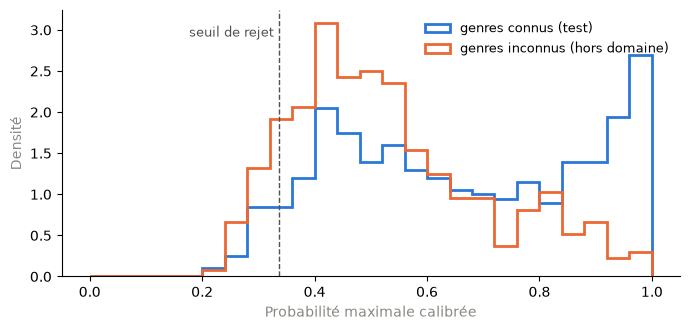

AUROC : 0.669 · hors domaine acceptés : 89% · genres connus conservés : 94% · Gospel acceptés : 92%


In [8]:
ood = report["out_of_domain"]
display(pd.DataFrame(report["calibration_on_test"]).T.round(3))

maest = predictions[predictions.system == "maest_layer12"]
logits = np.log(np.clip(maest[[f"p_{label}" for label in LABELS]].to_numpy(), 1e-12, 1)) / ood["temperature"]
scaled = np.exp(logits - logits.max(axis=1, keepdims=True))
confidence = (scaled / scaled.sum(axis=1, keepdims=True)).max(axis=1)
roles = maest.role.to_numpy()

fig, ax = plt.subplots(figsize=(7, 3.4))
bins = np.linspace(0, 1, 26)
ax.hist(confidence[roles == "test"], bins=bins, density=True, histtype="step", linewidth=2, color=ACCENT,
        label="genres connus (test)")
ax.hist(confidence[roles == "ood"], bins=bins, density=True, histtype="step", linewidth=2, color=SECOND,
        label="genres inconnus (hors domaine)")
ax.axvline(ood["threshold"], color=CONTEXT, linestyle="--", linewidth=1)
ax.text(ood["threshold"] - 0.01, ax.get_ylim()[1] * 0.9, "seuil de rejet", color=CONTEXT, fontsize=9, ha="right")
ax.set_xlabel("Probabilité maximale calibrée", color=MUTED)
ax.set_ylabel("Densité", color=MUTED)
ax.legend(frameon=False, fontsize=9)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
plt.tight_layout()
plt.show()
print(f"AUROC : {ood['ood']['auroc']:.3f} · hors domaine acceptés : {ood['ood']['fpr_at_threshold']:.0%} · "
      f"genres connus conservés : {ood['ood']['in_domain_retention']:.0%} · "
      f"Gospel acceptés : {ood['gospel_probe']['fpr_at_threshold']:.0%}")

**Lecture.**
- **La température aggrave l'ECE sur le test** : le modèle y est moins précis que sur le développement, et la température le rend trop sûr de lui.
- **Les deux distributions de confiance se recouvrent largement.** Le seuil laisse donc passer la plupart des morceaux de genres inconnus.

## Conclusion

| Constat | Ce que montrent les données |
|---|---|
| Encodeur audio préentraîné | MAEST, gelé, dépasse nettement le ViT d'images et le CNN entraîné de zéro |
| Gain de la V1 | Même sens sur le test neuf, mais non significatif |
| Validation croisée | Elle surestime la performance sur de nouveaux artistes, même groupée par artiste |
| Calibration et rejet | Réglés sur le développement, ils doivent être revalidés sur des données neuves avant tout usage |

Limites et détails : `docs/RAPPORT_V2.md` et `docs/FICHE_MODELE_V2.md`.